# 04 — Estudo de caso: comparar as oito combinações

Este caderno adapta os estudos de caso do professor às combinações de IA, ansiedade e estudo. O objetivo é distinguir: (a) diferenças descritivas entre células; (b) dispersão/heterocedasticidade; e (c) inferência sobre contrastes fatoriais. Não inferir causalidade a partir dos gráficos.

In [1]:

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sys
from pathlib import Path

_plot_dir = next(
    (
        candidate
        for parent in (Path.cwd(), *Path.cwd().parents)
        for candidate in (
            parent,
            parent / "notebooks_adaptados",
            parent / "entrega2" / "notebooks_adaptados",
        )
        if (candidate / "visualizacoes.py").is_file()
    ),
    None,
)
if _plot_dir is None:
    raise FileNotFoundError("Não encontrei visualizacoes.py junto aos notebooks adaptados.")
sys.path.insert(0, str(_plot_dir))

import sys
from pathlib import Path

_plot_dir = next(
    (
        candidate
        for parent in (Path.cwd(), *Path.cwd().parents)
        for candidate in (
            parent,
            parent / "notebooks_adaptados",
            parent / "entrega2" / "notebooks_adaptados",
        )
        if (candidate / "visualizacoes.py").is_file()
    ),
    None,
)
if _plot_dir is None:
    raise FileNotFoundError("Não encontrei visualizacoes.py junto aos notebooks adaptados.")
sys.path.insert(0, str(_plot_dir))

import sys
from pathlib import Path

_plot_dir = next(
    (
        candidate
        for parent in (Path.cwd(), *Path.cwd().parents)
        for candidate in (
            parent,
            parent / "notebooks_adaptados",
            parent / "entrega2" / "notebooks_adaptados",
        )
        if (candidate / "visualizacoes.py").is_file()
    ),
    None,
)
if _plot_dir is None:
    raise FileNotFoundError("Não encontrei visualizacoes.py junto aos notebooks adaptados.")
sys.path.insert(0, str(_plot_dir))

import sys
from pathlib import Path

_plot_dir = next(
    (
        candidate
        for parent in (Path.cwd(), *Path.cwd().parents)
        for candidate in (
            parent,
            parent / "notebooks_adaptados",
            parent / "entrega2" / "notebooks_adaptados",
        )
        if (candidate / "visualizacoes.py").is_file()
    ),
    None,
)
if _plot_dir is None:
    raise FileNotFoundError("Não encontrei visualizacoes.py junto aos notebooks adaptados.")
sys.path.insert(0, str(_plot_dir))

from visualizacoes import (
    configure_plots, plot_cell_counts, plot_factorial_cube,
    plot_protocol_flow, plot_quality_dashboard, save_figure,
)
from scipy import stats
from IPython.display import display

configure_plots()

DATA_NAME = "ai_student_impact_dataset.csv"
ROOT = next(
    (base for base in (Path.cwd(), *Path.cwd().parents)
     if (base / "csv" / DATA_NAME).is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError(
        f"Não encontrei csv/{DATA_NAME} em nenhum diretório ancestral "
        f"do diretório atual: {Path.cwd()}"
    )
CSV_PATH = ROOT / "csv" / DATA_NAME
df = pd.read_csv(CSV_PATH)

required = {
    "Student_ID", "Major_Category", "Year_of_Study", "Pre_Semester_GPA",
    "Post_Semester_GPA", "Primary_Use_Case", "Anxiety_Level_During_Exams",
    "Traditional_Study_Hours",
}
missing_columns = required.difference(df.columns)
if missing_columns:
    raise ValueError(f"Colunas obrigatórias ausentes no CSV: {sorted(missing_columns)}")

df["Delta_GPA"] = df["Post_Semester_GPA"] - df["Pre_Semester_GPA"]
PASSIVE_USE_CASES = {"Copywriting/Drafting", "Direct_Answer_Generation"}
df["A"] = np.where(df["Primary_Use_Case"].isin(PASSIVE_USE_CASES), 1, -1)
stem_junior = df.loc[
    (df["Major_Category"] == "STEM") & (df["Year_of_Study"] == "Junior")
].copy()

ANXIETY_Q2 = stem_junior["Anxiety_Level_During_Exams"].median()
STUDY_Q2 = stem_junior["Traditional_Study_Hours"].median()
stem_junior["B"] = np.where(
    stem_junior["Anxiety_Level_During_Exams"] > ANXIETY_Q2, 1, -1
)
stem_junior["C"] = np.where(
    stem_junior["Traditional_Study_Hours"] > STUDY_Q2, 1, -1
)
factorial = stem_junior.copy()

YATES = ["(1)", "a", "b", "ab", "c", "ac", "bc", "abc"]
CELLS = [
    (a, b, c)
    for c in (-1, 1)
    for b in (-1, 1)
    for a in (-1, 1)
]
cell_number = {cell: number for number, cell in enumerate(CELLS, start=1)}
factorial["celula"] = [
    cell_number[(int(row.A), int(row.B), int(row.C))]
    for row in factorial[["A", "B", "C"]].itertuples(index=False)
]
groups = {
    key: frame["Delta_GPA"].to_numpy()
    for key, frame in factorial.groupby(["A", "B", "C"], sort=False)
}
cell_counts = factorial.groupby(["A", "B", "C"]).size()
if set(groups) != set(CELLS):
    raise ValueError("A classificação não produziu as oito células fatoriais.")
if factorial["Delta_GPA"].isna().any():
    raise ValueError("Há ΔGPA ausente; resolva os dados ausentes antes da análise.")

print(f"Arquivo: {CSV_PATH}")
print(f"Dataset completo: n={len(df):,}")
print(f"Recorte STEM + Junior: n={len(stem_junior):,}")
print(f"Analisados nas oito células: n={len(factorial):,}")
print(f"Cortes: ansiedade Q2={ANXIETY_Q2:g}; estudo Q2={STUDY_Q2:.2f} h")
print(f"Menor célula: n={cell_counts.min():,}")

configure_plots()


Arquivo: /home/wagner/pcc170/entrega2-com_notebooks_adaptados/entrega2-com_notebooks_adaptados/csv/ai_student_impact_dataset.csv
Dataset completo: n=50,000
Recorte STEM + Junior: n=3,279
Analisados nas oito células: n=3,279
Cortes: ansiedade Q2=4; estudo Q2=10.91 h
Menor célula: n=181


## Resumo por célula e homogeneidade de variâncias

,n,media,mediana,dp
"1 (A, Ans−, Est−)",667,0.196,0.179,0.172
"2 (P, Ans−, Est−)",210,0.152,0.170,0.198
"3 (A, Ans+, Est−)",576,0.201,0.200,0.184
"4 (P, Ans+, Est−)",187,0.091,0.121,0.236
"5 (A, Ans−, Est+)",639,0.317,0.308,0.170
"6 (P, Ans−, Est+)",235,0.252,0.259,0.176
"7 (A, Ans+, Est+)",584,0.323,0.309,0.173
"8 (P, Ans+, Est+)",181,0.233,0.246,0.179


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


Brown–Forsythe/Levene entre células: estatística=4.734; p=2.65e-05
Figura salva: 04_distribuicao_bruta_por_celula.png (PNG) e 04_distribuicao_bruta_por_celula.pdf (PDF)


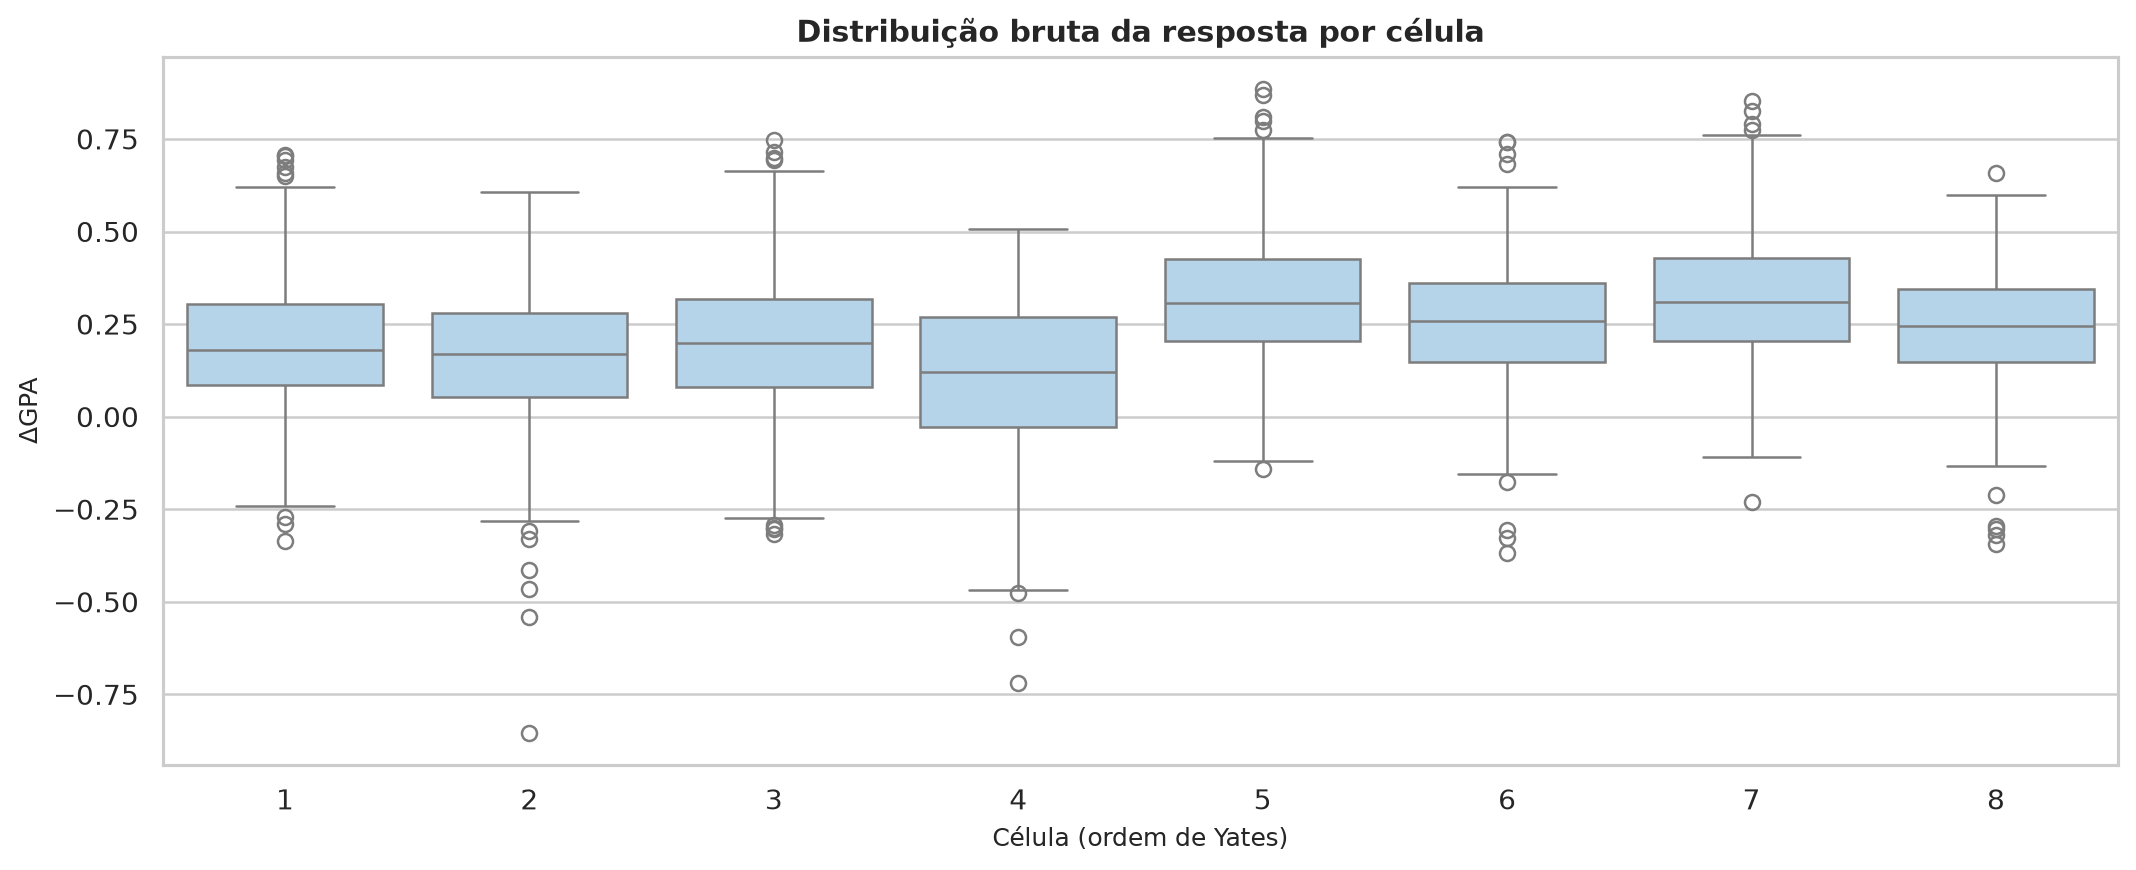

In [2]:

cell_summary = (
    factorial.groupby(["A", "B", "C"])["Delta_GPA"]
    .agg(n="size", media="mean", mediana="median", dp="std")
    .reindex(CELLS)
)
cell_summary.index = [
    f"{i + 1} ({'P' if a == 1 else 'A'}, {'Ans+' if b == 1 else 'Ans−'}, {'Est+' if c == 1 else 'Est−'})"
    for i, (a, b, c) in enumerate(CELLS)
]
display(cell_summary.round(3))
levene = stats.levene(
    *[groups[cell] for cell in CELLS],
    center="median",
)
print(f"Brown–Forsythe/Levene entre células: estatística={levene.statistic:.3f}; p={levene.pvalue:.3g}")

plt.figure(figsize=(12, 5))
sns.boxplot(data=factorial, x="celula", y="Delta_GPA", order=range(1, 9), color="#aed6f1")
plt.xlabel("Célula (ordem de Yates)")
plt.ylabel("ΔGPA")
plt.title("Distribuição bruta da resposta por célula")
plt.tight_layout()
save_figure(plt.gcf(), "04_distribuicao_bruta_por_celula")


### Médias por célula com intervalos bootstrap

Intervalos descritivos de médias dentro das células; não substituem o HC3 para testes entre fatores.

Figura salva: 04_medias_ic_bootstrap_celulas.png (PNG) e 04_medias_ic_bootstrap_celulas.pdf (PDF)


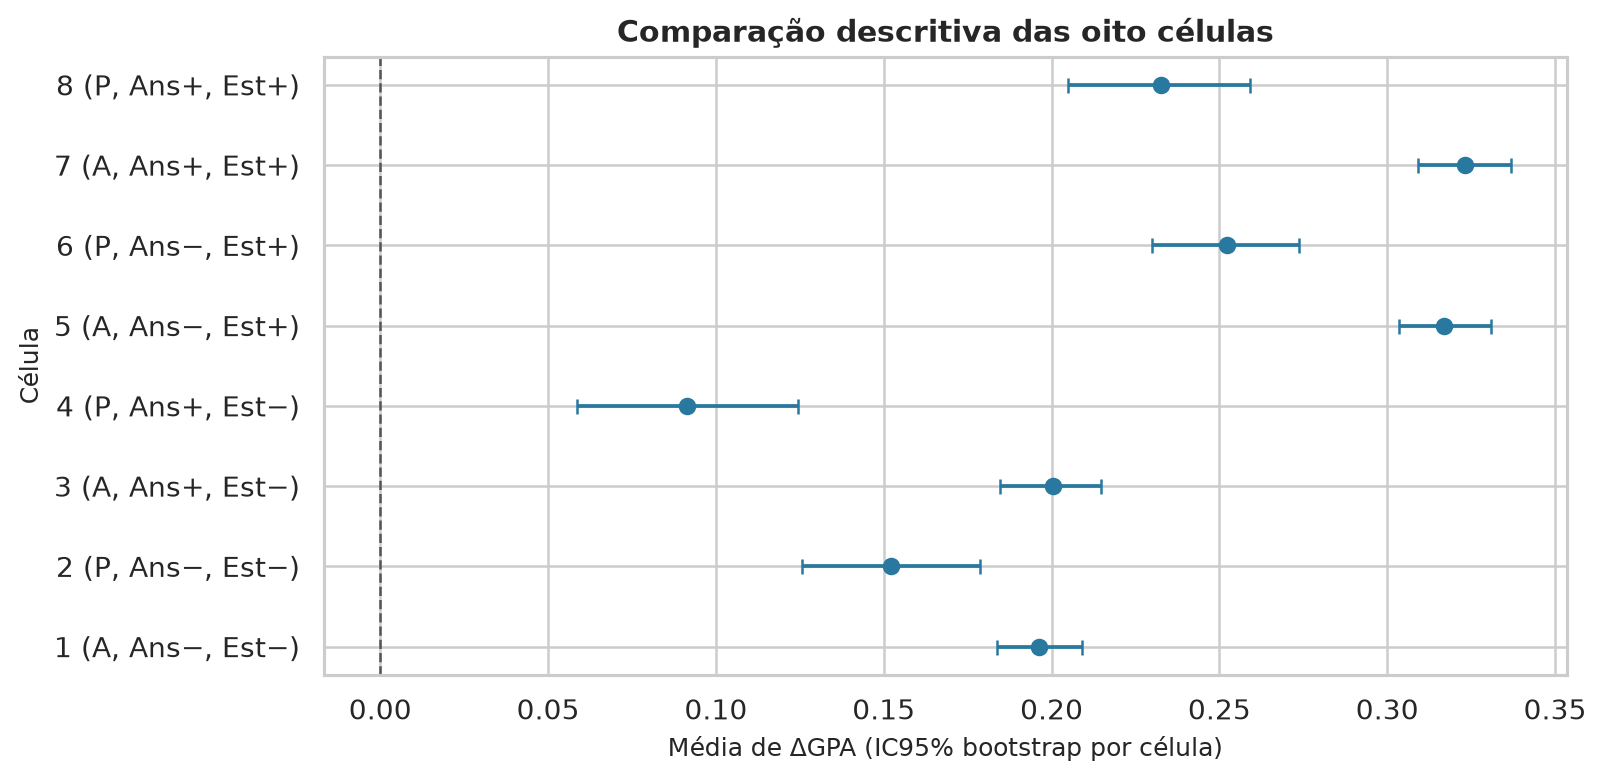

In [3]:
rng_cell = np.random.default_rng(42)
cell_bootstrap = {}
for cell in CELLS:
    values = groups[cell]
    samples = values[rng_cell.integers(0, len(values), size=(2000, len(values)))]
    cell_bootstrap[cell] = np.quantile(samples.mean(axis=1), [0.025, 0.975])

means = np.array([groups[cell].mean() for cell in CELLS])
lower = np.array([means[i] - cell_bootstrap[cell][0] for i, cell in enumerate(CELLS)])
upper = np.array([cell_bootstrap[cell][1] - means[i] for i, cell in enumerate(CELLS)])
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.errorbar(
    means, np.arange(len(CELLS)),
    xerr=np.vstack([lower, upper]),
    fmt="o", capsize=3, color="#2878a0",
)
ax.axvline(0, color="#555555", linestyle="--", linewidth=1)
ax.set_yticks(np.arange(len(CELLS)), [
    f"{i + 1} ({'P' if a == 1 else 'A'}, {'Ans+' if b == 1 else 'Ans−'}, {'Est+' if c == 1 else 'Est−'})"
    for i, (a, b, c) in enumerate(CELLS)
])
ax.set(xlabel="Média de ΔGPA (IC95% bootstrap por célula)", ylabel="Célula")
ax.set_title("Comparação descritiva das oito células")
save_figure(fig, "04_medias_ic_bootstrap_celulas")


## Diagnóstico do modelo fatorial bruto

A ANOVA é ajustada aos alunos, não às médias de bootstrap. Os gráficos ajudam a avaliar forma dos resíduos e variância não constante; HC3 é a correção robusta usada para a inferência principal.

Figura salva: 04_diagnosticos_residuos.png (PNG) e 04_diagnosticos_residuos.pdf (PDF)


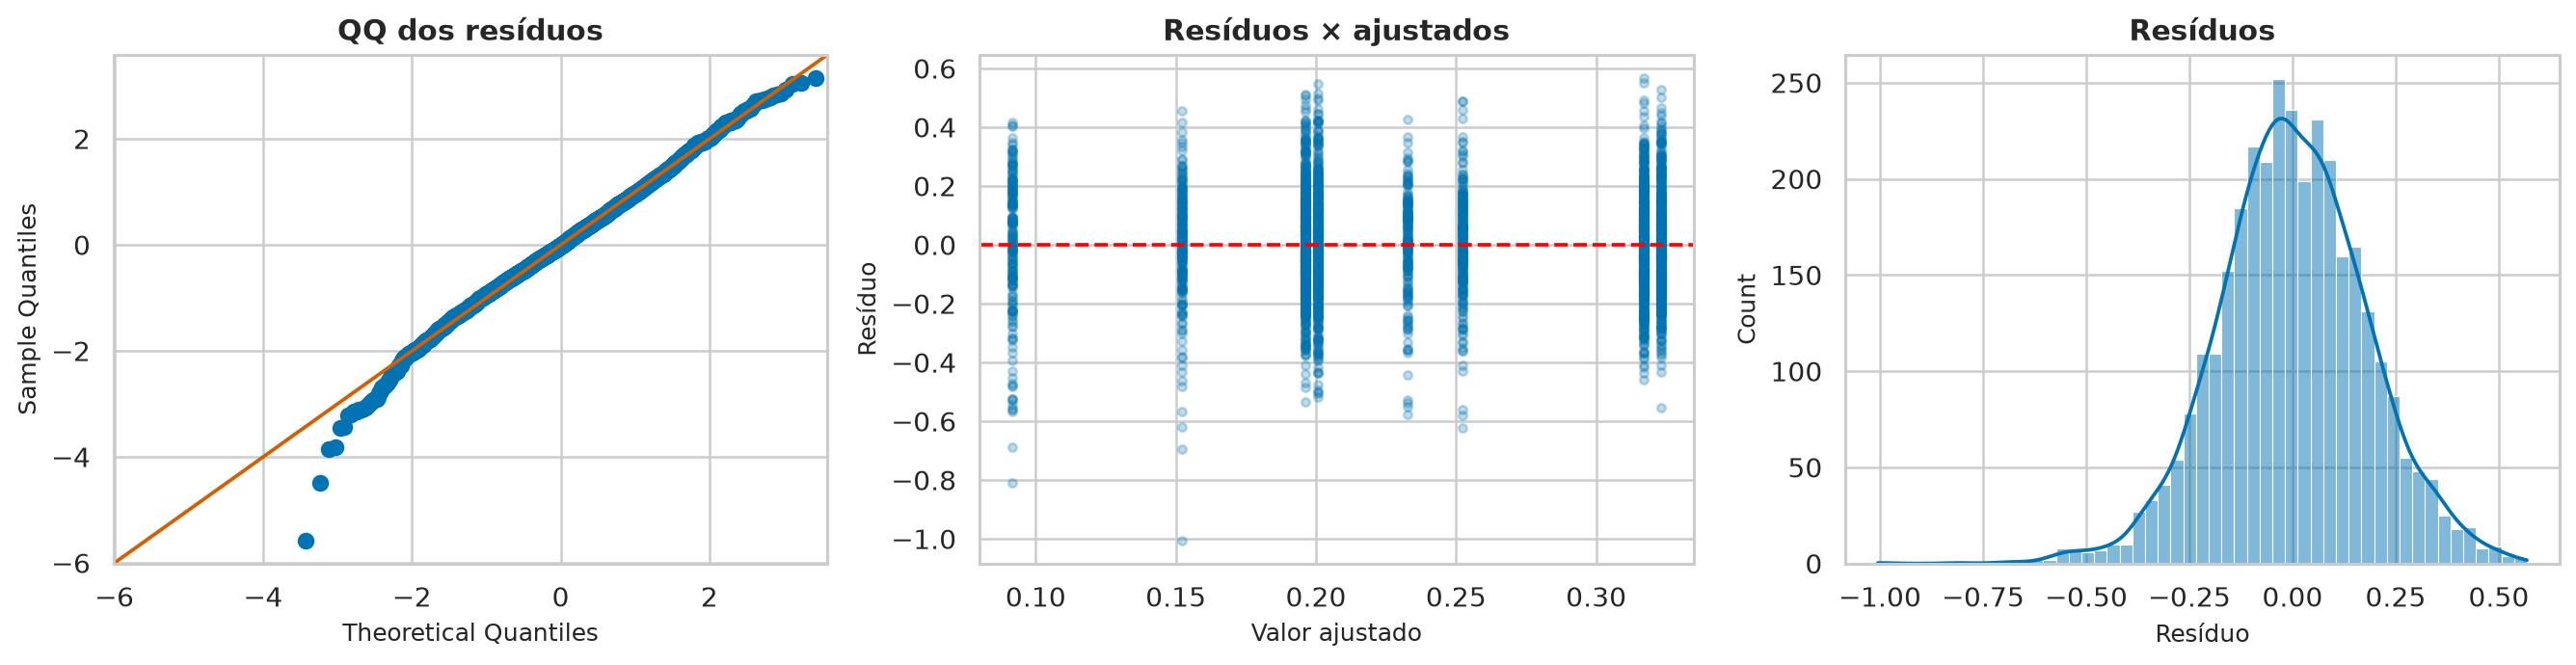

R² do modelo saturado: 0.129
Teste de Shapiro dos resíduos (diagnóstico, não decisão isolada): p=0.000


In [4]:

import statsmodels.formula.api as smf
import statsmodels.api as sm

model = smf.ols("Delta_GPA ~ A * B * C", data=factorial).fit()
residuals = model.resid
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sm.qqplot(residuals, line="45", fit=True, ax=axes[0])
axes[0].set_title("QQ dos resíduos")
axes[1].scatter(model.fittedvalues, residuals, alpha=0.25, s=12)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set(title="Resíduos × ajustados", xlabel="Valor ajustado", ylabel="Resíduo")
sns.histplot(residuals, kde=True, ax=axes[2])
axes[2].set(title="Resíduos", xlabel="Resíduo")
plt.tight_layout()
save_figure(fig, "04_diagnosticos_residuos")
print(f"R² do modelo saturado: {model.rsquared:.3f}")
print(
    "Teste de Shapiro dos resíduos (diagnóstico, não decisão isolada): "
    f"p={stats.shapiro(residuals).pvalue:.3f}"
)


## Conclusão do caso

A heterocedasticidade observada (Levene bruto **p ≈ 2,6×10⁻⁵**) impede tratar a variância comum como garantida. Por isso, a inferência de termos usa erros-padrão HC3 e os intervalos dos efeitos usam bootstrap estratificado. Os resíduos têm cauda inferior associada ao limite superior do GPA; não se aplica log a ΔGPA, que pode ser zero ou negativo.